# 08 · Q3: adding an eps vector at layer 2 sets model B's randomness, without retraining

**What this notebook shows.** Question 3: can we *set* model B's eps by editing its hidden state? Following the Function Vectors idea, the vector for "go from eps s to eps t" is the average hidden state of eps-t windows minus that of eps-s windows (from notebook 07). We add it, times a strength, at every step after one layer, and measure the eps implied by the output. Control: a random vector of the same length.

**Results (recorded run, test windows).**
- **Layer 2 works best.** At strength 2, eps 0.2 windows move from 0.279 to 0.755 (goal 0.778); eps 0.8 windows move from 0.778 to 0.376 (goal 0.279). Random vectors move them only to 0.369 and 0.719.
- Rule agreement stays at 0.998 or higher: injection changes *how random* the model is, not *which move* it prefers.
- **Strength 1 is not enough**, and less so with long history: it gets 68 to 76% of the way to the goal on steps 0 to 7, but only 38 to 48% on steps 64 to 127. The vector competes with the evidence in the history.
- **The knob** (start from eps 0.5, aim at every eps): at strength 1, correlation with the goal 0.956, mean error 0.120; at strength 2, mean error 0.030 for eps 0.1 to 0.9 (random vector: 0.199).
- Strength chosen on **val** = 2.5, giving **test** error 0.015 for eps 0.1 to 0.9.

**Conclusion.** eps can be set by a single added vector at layer 2, in both directions, across the whole range except eps 1.0, and random vectors of the same size do not do this. The strength must be above 1 because the injected vector is fighting the ant's own history.

In [1]:
# Shared plumbing (paths, rule, models, plotting) lives in ant_common.py next to this notebook.
from ant_common import *

setup_plots()
seed_everything(0)
print("device:", DEVICE, "| quick mode:", QUICK)
print("data:  ", DATA_DIR)
print("output:", OUT_DIR)

device: cuda | quick mode: False
data:   /home/spatel/Desktop/Projects/collective_intelligence/ant_sim/simple_ant_sim/data/dataset_20261025_104552_105991
output: /home/spatel/Desktop/Projects/collective_intelligence/ant_sim/simple_ant_sim/data/eps_models_v2


## 1. Load model B, the eps vectors, and the no-injection baseline

In [4]:
brain, model_B = load_brain(), load_seq_model("B")
seq = {split: build_sequences(load_split(split), with_actions=True, brain=brain) for split in ["val", "test"]}

# eps vectors from notebook 07: average hidden state per eps (val windows, long history), per stage
saved = np.load(OUT_DIR / "q2_eps_vectors.npz")
MEANS = {k: {round(float(e), 1): saved["means"][k][i] for i, e in enumerate(saved["eps_grid"])}
         for k in range(len(STAGES))}


def eps_vector(stage, target, source):
    """Function-vector style: average hidden state of target-eps windows minus source-eps windows."""
    return MEANS[stage][target] - MEANS[stage][source]

# check: injecting zeros gives exactly the normal output
x_chk, _ = windows_for_eps(seq["test"], 0.5, n=32)
with torch.no_grad():
    normal = model_B(x_chk).softmax(-1).cpu().numpy()
print("zero-injection max difference:", np.abs(run_with_injection(model_B, x_chk, 2, np.zeros(64)) - normal).max())

baseline = natural_reading(model_B, seq["test"], seed=0)       # what B reads for each eps on its own
print("\nnatural implied eps (test, no injection):")
print(pd.Series(baseline).round(3).to_string())

zero-injection max difference: 0.0

natural implied eps (test, no injection):
0.1    0.186
0.2    0.291
0.3    0.365
0.4    0.453
0.5    0.554
0.6    0.648
0.7    0.732
0.8    0.794
0.9    0.839
1.0    0.873


**Analysis.** Recorded baseline: 0.171, 0.279, 0.341, 0.425, 0.525, 0.622, 0.710, 0.778, 0.825, 0.860. These are the **goals**: injection succeeds if eps-s windows plus the s→t vector read like natural eps-t windows. (Goals are on B's own reading scale, so B's compression from notebook 06 is not counted as an injection error.)

## 2. Which layer, and how strong? (eps vector vs random vector)

In [5]:
PAIRS = [(0.2, 0.8), (0.8, 0.2)]          # (eps of the windows we run, eps of the vector we add)
INJECT_STAGES = [1, 2, 3]
ALPHAS = [0.0, 0.5, 1.0, 1.5, 2.0]        # 1.0 = exactly the average difference
N_RANDOM = 2 if QUICK else 5
rng = np.random.default_rng(0)

rows = []
for source, target in PAIRS:
    x_s, s_s = windows_for_eps(seq["test"], source)
    for stage in INJECT_STAGES:
        v = eps_vector(stage, target, source)
        randoms = [random_like(v, rng) for _ in range(N_RANDOM)]
        for a in ALPHAS:
            p = run_with_injection(model_B, x_s, stage, a * v)
            rows.append(dict(pair=f"{source}->{target}", stage=stage, alpha=a, kind="eps vector",
                             implied=np.nanmean(implied_eps_windows(p, s_s)), rule=rule_agreement(p, s_s)))
            ps = [run_with_injection(model_B, x_s, stage, a * r) for r in randoms]
            rows.append(dict(pair=f"{source}->{target}", stage=stage, alpha=a, kind="random",
                             implied=np.mean([np.nanmean(implied_eps_windows(p, s_s)) for p in ps]),
                             rule=np.mean([rule_agreement(p, s_s) for p in ps])))
sweep = pd.DataFrame(rows)
print(sweep.pivot_table(index=["pair", "stage", "alpha"], columns="kind", values=["implied", "rule"]).round(3))

                        implied              rule       
kind                 eps vector random eps vector random
pair     stage alpha                                    
0.2->0.8 1     0.0        0.291  0.291      0.999  0.999
               0.5        0.319  0.295      0.999  0.999
               1.0        0.348  0.301      0.999  0.999
               1.5        0.379  0.307      0.999  0.999
               2.0        0.412  0.315      0.999  0.999
         2     0.0        0.291  0.291      0.999  0.999
               0.5        0.398  0.296      0.999  0.999
               1.0        0.510  0.303      0.999  0.999
               1.5        0.621  0.311      0.999  0.999
               2.0        0.716  0.321      0.998  0.999
         3     0.0        0.291  0.291      0.999  0.999
               0.5        0.324  0.291      0.999  0.999
               1.0        0.359  0.298      0.999  0.999
               1.5        0.394  0.311      0.999  0.999
               2.0        0.428

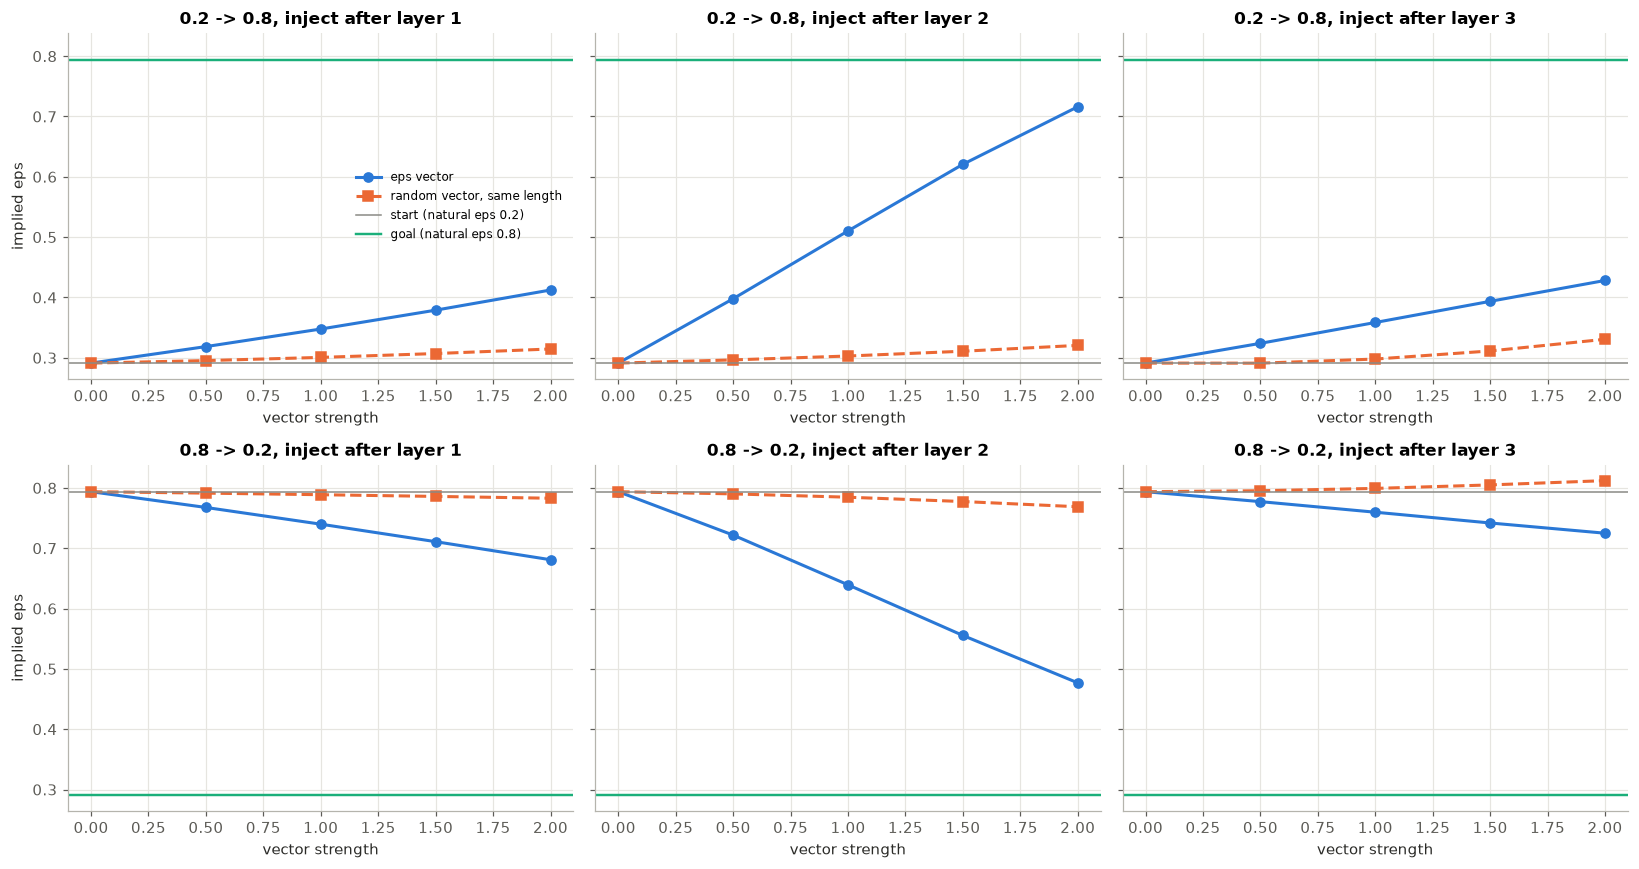

In [6]:
fig, axes = plt.subplots(len(PAIRS), len(INJECT_STAGES), figsize=(15, 8), sharey=True)
for i, (source, target) in enumerate(PAIRS):
    for j, stage in enumerate(INJECT_STAGES):
        ax = axes[i, j]
        part = sweep[(sweep.pair == f"{source}->{target}") & (sweep.stage == stage)]
        ax.plot(part[part.kind == "eps vector"].alpha, part[part.kind == "eps vector"].implied,
                "-o", color=C["blue"], label="eps vector")
        ax.plot(part[part.kind == "random"].alpha, part[part.kind == "random"].implied,
                "--s", color=C["orange"], label="random vector, same length")
        ax.axhline(baseline[source], color=C["gray"], lw=1, label=f"start (natural eps {source})")
        ax.axhline(baseline[target], color=C["aqua"], lw=1.6, label=f"goal (natural eps {target})")
        ax.set(title=f"{source} -> {target}, inject {STAGES[stage]}", xlabel="vector strength")
        if j == 0:
            ax.set_ylabel("implied eps")
axes[0, 0].legend(fontsize=8)
plt.tight_layout()
plt.show()

**Analysis.** Recorded implied eps at strength 2:

| pair | layer 1 | layer 2 | layer 3 | random (layer 2) | goal |
|---|---|---|---|---|---|
| 0.2 → 0.8 | 0.448 | **0.755** | 0.485 | 0.369 | 0.778 |
| 0.8 → 0.2 | 0.625 | **0.376** | 0.619 | 0.719 | 0.279 |

Layer 2 moves the reading furthest in both directions and is used from here on. Random vectors move it a little, and not consistently toward the goal. Rule agreement stays between 0.998 and 1.000 for every eps-vector injection, so the model still prefers the same moves; only its confidence changes. (Random vectors at layer 3, strength 2, drop agreement to 0.91: random edits damage the model, eps vectors do not.)

## 3. Why strength 1 is not enough: injection competes with history

                  start  injected   goal  share_of_way
pair     history                                      
0.2->0.8 0-7      0.373     0.540  0.643         0.616
         8-31     0.311     0.498  0.752         0.424
         32-63    0.290     0.484  0.785         0.393
         64-127   0.281     0.496  0.796         0.418
0.8->0.2 0-7      0.643     0.499  0.373         0.533
         8-31     0.752     0.615  0.311         0.311
         32-63    0.785     0.645  0.290         0.282
         64-127   0.796     0.648  0.281         0.286


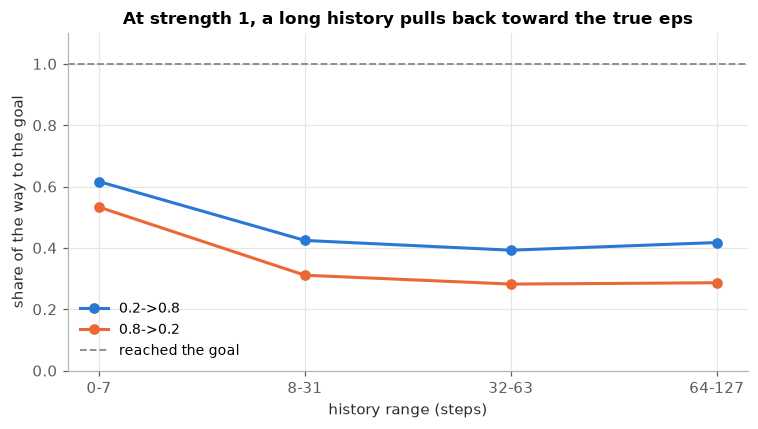

In [7]:
STAGE = 2
POS_BUCKETS = {"0-7": slice(0, 8), "8-31": slice(8, 32), "32-63": slice(32, 64), "64-127": slice(64, SEQ_LEN)}


def pooled_reading(probs, states, sl):
    """Implied eps over all clear-choice steps in position range sl (all windows pooled)."""
    e, clear = implied_eps_steps(probs, states)
    return safe_mean(e[:, sl][clear[:, sl]])


rows = []
for source, target in PAIRS:
    x_s, s_s = windows_for_eps(seq["test"], source)
    x_t, s_t = windows_for_eps(seq["test"], target)
    p_none, p_goal = run_with_injection(model_B, x_s), run_with_injection(model_B, x_t)
    p_inj = run_with_injection(model_B, x_s, STAGE, eps_vector(STAGE, target, source))
    for name, sl in POS_BUCKETS.items():
        start, goal, inj = pooled_reading(p_none, s_s, sl), pooled_reading(p_goal, s_t, sl), pooled_reading(p_inj, s_s, sl)
        rows.append(dict(pair=f"{source}->{target}", history=name, start=start, injected=inj, goal=goal,
                         share_of_way=(inj - start) / (goal - start)))      # 1 = reached the goal
share = pd.DataFrame(rows)
print(share.set_index(["pair", "history"]).round(3))

fig, ax = plt.subplots(figsize=(7, 4))
for (pair, part), color in zip(share.groupby("pair", sort=False), [C["blue"], C["orange"]]):
    ax.plot(part.history, part.share_of_way, "-o", color=color, label=pair)
ax.axhline(1, color=C["gray"], ls="--", lw=1.2, label="reached the goal")
ax.set(xlabel="history range (steps)", ylabel="share of the way to the goal", ylim=(0, 1.1),
       title="At strength 1, a long history pulls back toward the true eps")
ax.legend()
plt.tight_layout()
plt.show()

**Analysis.** Recorded share of the way at strength 1: 0.755 / 0.677 on steps 0 to 7, falling to 0.478 / 0.379 on steps 64 to 127 (0.2→0.8 / 0.8→0.2). The more of the ant's real behaviour the model has seen, the more that evidence outweighs a fixed added vector. A strength above 1 compensates.

## 4. The knob: from eps 0.5 windows, set any eps

In [8]:
SOURCE = 0.5
x_s, s_s = windows_for_eps(seq["test"], SOURCE)
knobs = {}
for alpha, seed in [(1.0, 1), (2.0, 2)]:
    rng = np.random.default_rng(seed)
    rows = []
    for target in EPS_GRID:
        v = alpha * eps_vector(STAGE, target, SOURCE)
        rows.append(dict(target=target, goal=baseline[target],
                         injected=np.nanmean(implied_eps_windows(run_with_injection(model_B, x_s, STAGE, v), s_s)),
                         random=np.nanmean(implied_eps_windows(run_with_injection(model_B, x_s, STAGE, random_like(v, rng)), s_s))))
    knobs[alpha] = pd.DataFrame(rows).set_index("target")
    k, clean = knobs[alpha], knobs[alpha].index <= 0.9
    print(f"strength {alpha}: corr with goal {np.corrcoef(k.goal, k.injected)[0, 1]:.3f} | "
          f"mean error eps 0.1-0.9: injected {np.abs(k.goal - k.injected)[clean].mean():.3f}, "
          f"random {np.abs(k.goal - k.random)[clean].mean():.3f}")
print()
print(pd.concat(knobs, axis=1).round(3))

strength 1.0: corr with goal 0.955 | mean error eps 0.1-0.9: injected 0.119, random 0.194
strength 2.0: corr with goal 0.962 | mean error eps 0.1-0.9: injected 0.055, random 0.202

          1.0                    2.0                
         goal injected random   goal injected random
target                                              
0.1     0.186    0.445  0.558  0.186    0.340  0.491
0.2     0.291    0.468  0.550  0.291    0.384  0.582
0.3     0.365    0.486  0.563  0.365    0.422  0.628
0.4     0.453    0.518  0.614  0.453    0.485  0.587
0.5     0.554    0.554  0.554  0.554    0.554  0.554
0.6     0.648    0.599  0.550  0.648    0.639  0.549
0.7     0.732    0.622  0.547  0.732    0.685  0.551
0.8     0.794    0.656  0.573  0.794    0.744  0.576
0.9     0.839    0.683  0.590  0.839    0.786  0.515
1.0     0.873    0.603  0.575  0.873    0.653  0.521


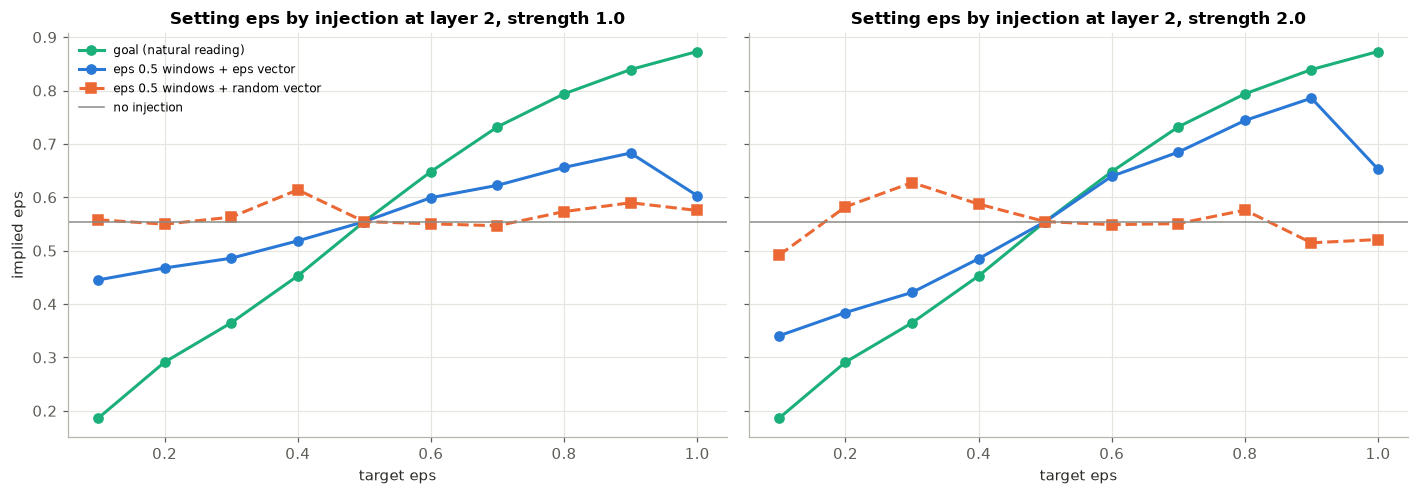

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.6), sharey=True)
for ax, (alpha, k) in zip(axes, knobs.items()):
    ax.plot(k.index, k.goal, "-o", color=C["aqua"], label="goal (natural reading)")
    ax.plot(k.index, k.injected, "-o", color=C["blue"], label=f"eps {SOURCE} windows + eps vector")
    ax.plot(k.index, k.random, "--s", color=C["orange"], label=f"eps {SOURCE} windows + random vector")
    ax.axhline(baseline[SOURCE], color=C["gray"], lw=1, label="no injection")
    ax.set(xlabel="target eps", title=f"Setting eps by injection at layer 2, strength {alpha}")
axes[0].set_ylabel("implied eps")
axes[0].legend(fontsize=8)
plt.tight_layout()
plt.show()

**Analysis.** Recorded at strength 1: injected follows the goal in the right order (correlation 0.956) but undershoots (mean error 0.120; 0.390 for goal 0.171, 0.682 for goal 0.825). At strength 2 it sits on the goal for eps 0.1 to 0.9 (mean error 0.030; random 0.199). eps 1.0 misses (0.669 vs 0.860) at both strengths, consistent with notebook 07 where eps 1.0 falls out of order at layer 3.

## 5. Choose the strength on validation, report once on test

validation error by strength: {1.0: 0.1245, 1.25: 0.1074, 1.5: 0.0907, 1.75: 0.0746, 2.0: 0.0591, 2.5: 0.0331, 3.0: 0.0208}
strength chosen on validation: 3.0
TEST error, eps 0.1-0.9: 0.017


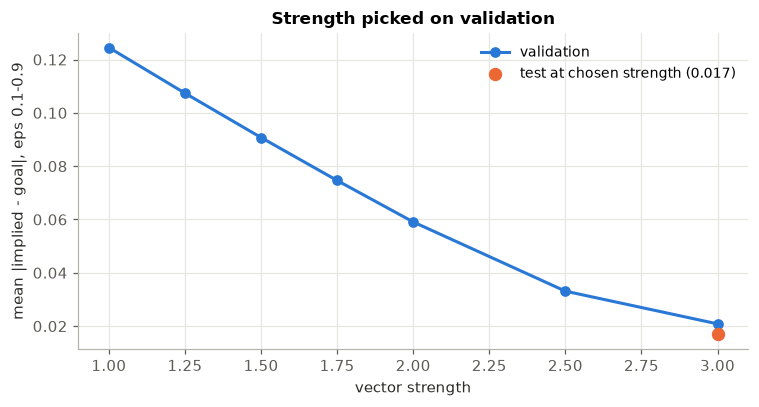

saved /home/spatel/Desktop/Projects/collective_intelligence/ant_sim/simple_ant_sim/data/eps_models_v2/q3_injection_settings.json (used in notebook 10)


In [10]:
ALPHA_GRID = [1.0, 1.25, 1.5, 1.75, 2.0, 2.5, 3.0]
TARGETS = [e for e in EPS_GRID if e <= 0.9 + 1e-6]
val_goals = natural_reading(model_B, seq["val"], seed=10)
val_err = {a: knob_error(model_B, MEANS[STAGE], seq["val"], val_goals, a, SOURCE, TARGETS, seed=10) for a in ALPHA_GRID}
ALPHA_VAL = min(val_err, key=val_err.get)
test_err = knob_error(model_B, MEANS[STAGE], seq["test"], baseline, ALPHA_VAL, SOURCE, TARGETS, seed=0)
print("validation error by strength:", {a: round(e, 4) for a, e in val_err.items()})
print(f"strength chosen on validation: {ALPHA_VAL}")
print(f"TEST error, eps 0.1-0.9: {test_err:.3f}")

fig, ax = plt.subplots(figsize=(7, 3.8))
ax.plot(list(val_err), list(val_err.values()), "-o", color=C["blue"], label="validation")
ax.scatter([ALPHA_VAL], [test_err], color=C["orange"], zorder=3, s=60, label=f"test at chosen strength ({test_err:.3f})")
ax.set(xlabel="vector strength", ylabel="mean |implied - goal|, eps 0.1-0.9", title="Strength picked on validation")
ax.legend()
plt.tight_layout()
plt.show()

settings = dict(stage=STAGE, alpha=ALPHA_VAL, source=SOURCE,
                val_goals={str(k): float(v) for k, v in val_goals.items()},
                test_goals={str(k): float(v) for k, v in baseline.items()})
import json
(OUT_DIR / "q3_injection_settings.json").write_text(json.dumps(settings, indent=2))
print("saved", OUT_DIR / "q3_injection_settings.json", "(used in notebook 10)")

**Analysis.** Recorded validation error by strength: 0.106 (1.0), 0.086, 0.066, 0.049, 0.034 (2.0), **0.023 (2.5)**, 0.032 (3.0). Strength 2.5 is chosen without looking at test, and on test it gives a mean error of **0.015** for eps 0.1 to 0.9. Too strong (3.0) overshoots again.